### Шаг 2.1 Импорты и загрузка данных

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Подключаем корень проекта для импорта из src/
project_root = Path.cwd().parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from src.stats import bootstrap_median, calc_distribution_stats

sns.set_theme(style="whitegrid")
plots_dir = project_root / "plots"
plots_dir.mkdir(exist_ok=True)

df = pd.read_parquet(project_root / "data" / "processed" / "clean.parquet")
print(f"Загружено строк: {len(df):,}")

Загружено строк: 11,696,725


### Шаг 2.2 Расчёт статистик и бутстрап-интервала (для Таблицы 2)

In [2]:
target = df["fare_amount"]

stats_res = calc_distribution_stats(target)
ci_low, ci_high = bootstrap_median(target, n_boot=2000, seed=42)

table_2 = pd.DataFrame({
    "Показатель": [
        "Среднее",
        "Медиана",
        "Асимметрия в исходной шкале",
        "Асимметрия после log1p",
        "95-процентный бутстрап-интервал медианы",
        "Число повторов бутстрапа",
    ],
    "Значение": [
        f"{stats_res['mean']:.4f}",
        f"{stats_res['median']:.4f}",
        f"{stats_res['skew_raw']:.4f}",
        f"{stats_res['skew_log1p']:.4f}",
        f"[{ci_low:.4f}; {ci_high:.4f}]",
        "2000",
    ],
})

display(table_2)

,Показатель,Значение
0,Среднее,9.5212
1,Медиана,8.5000
2,Асимметрия в исходной шкале,1.0354
3,Асимметрия после log1p,0.1298
4,95-процентный бутстрап-интервал медианы,[8.5000; 8.5000]
5,Число повторов бутстрапа,2000


### Шаг 2.3 Двойная гистограмма (исходный и логарифмический масштаб)

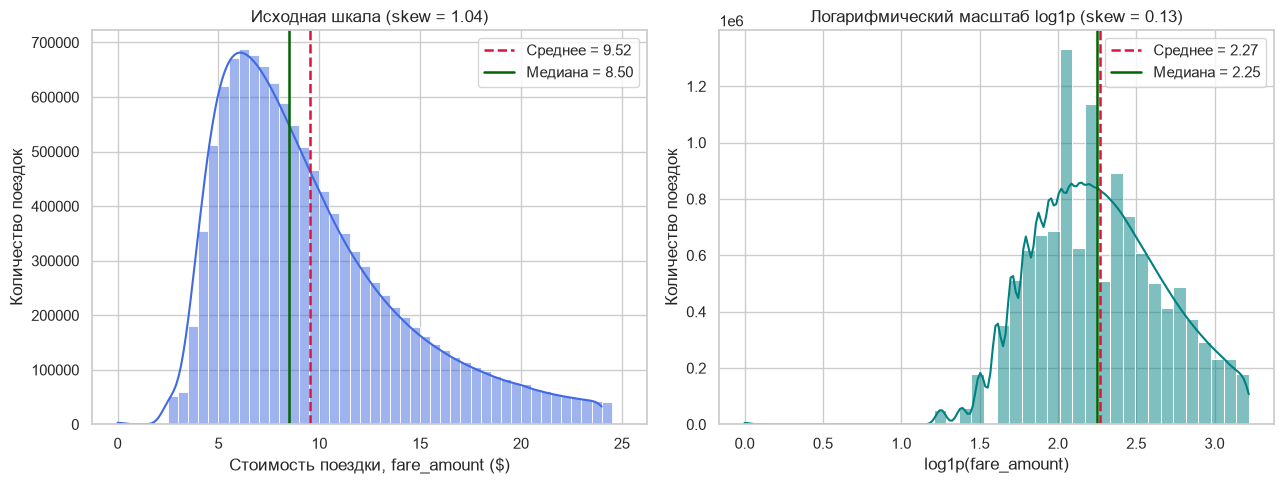

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Левая панель: исходная шкала
sns.histplot(
    target,
    binwidth=0.5,
    binrange=(0, 25),
    kde=True,
    kde_kws={"bw_adjust": 2},
    color="royalblue",
    ax=axes[0],
)
axes[0].axvline(stats_res["mean"], color="crimson", linestyle="--", linewidth=1.8, label=f"Среднее = {stats_res['mean']:.2f}")
axes[0].axvline(stats_res["median"], color="darkgreen", linestyle="-", linewidth=1.8, label=f"Медиана = {stats_res['median']:.2f}")
axes[0].set_title(f"Исходная шкала (skew = {stats_res['skew_raw']:.2f})")
axes[0].set_xlabel("Стоимость поездки, fare_amount ($)")
axes[0].set_ylabel("Количество поездок")
axes[0].legend()

# Правая панель: логарифмическая шкала log1p
log_target = np.log1p(target)
sns.histplot(
    log_target,
    bins=40,
    kde=True,
    kde_kws={"bw_adjust": 2},
    color="teal",
    ax=axes[1],
)
axes[1].axvline(log_target.mean(), color="crimson", linestyle="--", linewidth=1.8, label=f"Среднее = {log_target.mean():.2f}")
axes[1].axvline(log_target.median(), color="darkgreen", linestyle="-", linewidth=1.8, label=f"Медиана = {log_target.median():.2f}")
axes[1].set_title(f"Логарифмический масштаб log1p (skew = {stats_res['skew_log1p']:.2f})")
axes[1].set_xlabel("log1p(fare_amount)")
axes[1].set_ylabel("Количество поездок")
axes[1].legend()

plt.tight_layout()
plt.savefig(plots_dir / "lab3_01_hist_log1p.png", dpi=300)
plt.show()

**Наблюдение:** 
В исходной шкале распределение стоимости поездки (`fare_amount`) имеет выраженную правостороннюю асимметрию (`skew = 1,04`), из-за чего среднее = 9,52 $ заметно превышает медиану = 8,50 $. 
После логарифмирования `log1p` коэффициент асимметрии снижается в 8 раз — до 0,13 (почти симметричное распределение), а среднее = 2,27 и медиана = 2,25 практически совпадают.

### Формулировка трёх статистических гипотез (до проведения расчётов)

Уровень значимости для всех тестов: $\alpha = 0.05$.

1. **Гипотеза 1 (различие стоимости поездки между оплатой картой и наличными — из общего вывода ЛР 2):**
   * **Нулевая гипотеза ($H_0$):** Распределение и медианная стоимость поездки (`fare_amount`) при оплате банковской картой (`payment_type == 1`) и наличными (`payment_type == 2`) не различаются.
   * **Альтернативная гипотеза ($H_1$):** Медианная стоимость поездки при оплате картой выше, чем при оплате наличными.
   * **Статистический тест:** Двусторонний U-тест Манна-Уитни (`scipy.stats.mannwhitneyu`).
   * **Практически значимая величина различия:** Разность медиан не менее **0,50 $** (минимальный шаг таксометра в Нью-Йорке) или > 5 %.

2. **Гипотеза 2 (различие стоимости поездки по времени суток — утро, день, вечер, ночь):**
   * **Нулевая гипотеза ($H_0$):** Медианная стоимость поездки (`fare_amount`) одинакова во все периоды суток (ночь 0–5 ч, утро 6–11 ч, день 12–17 ч, вечер 18–23 ч).
   * **Альтернативная гипотеза ($H_1$):** Хотя бы в одном периоде суток стоимость поездки статистически значимо отличается от остальных.
   * **Статистический тест:** Критерий Краскела-Уоллиса (`scipy.stats.kruskal`), а при значимом результате — попарные тесты Манна-Уитни с поправкой Холма (`multipletests(..., method="holm")`).
   * **Практически значимая величина различия:** Разность медиан между периодами суток от **0,50 $** и более.

3. **Гипотеза 3 (изменение доли дальних поездок > 15 $ во время снежной бури в Нью-Йорке 26–27 января 2015 г.):**
   * **Нулевая гипотеза ($H_0$):** Доля поездок со стоимостью выше 15 $ (`fare_amount > 15`) во время снежной бури (26–27 января 2015 г., исторический шторм Juno в Нью-Йорке) не отличается от доли таких поездок в обычные дни января.
   * **Альтернативная гипотеза ($H_1$):** Доля дорогих/дальних поездок во время снежной бури статистически значимо изменилась по сравнению с обычными днями.
   * **Статистический тест:** z-тест для двух долей (`statsmodels.stats.proportion.proportions_ztest`).
   * **Практически значимая величина различия:** Изменение доли не менее чем на **1,0 процентный пункт (п.п.)**.